# Kiểm thử & Thực nghiệm Dự đoán Ảnh AI / Thật (Single, Batch & JPEG Stress Test)

Notebook này được nâng cấp phục vụ việc **kiểm thử nhanh mọi ảnh bất kỳ** (ảnh từ dataset hoặc ảnh ngoài thực tế/mạng xã hội) qua toàn bộ hệ thống **3 Nhánh Đơn & Stage 2 Fusion**:

### Các mô hình được nạp đối chiếu (6 mô hình chuẩn):
1. **3 Nhánh Đơn Độc lập:**
   - **Spatial (`EfficientNet-B0`)**: `best_spatial.pth` (`1280-D`, Pixel cục bộ)
   - **Semantic (`OpenAI CLIP ViT-B/16 Linear Probe`)**: `best_semantic.pth` (`512-D`, Ngữ nghĩa toàn cục)
   - **Spectral (`2D FFT Residual CNN`)**: `best_spectral.pth` (`256-D`, Phổ tần số)
2. **3 Mô hình Hợp nhất Stage 2:**
   - **FusionMLP Baseline (`p=0.0`, 3 nhánh)**: `best_fusion.pth` (`2048-D`)
   - **FusionMLP Branch Dropout (`p=0.15`, 3 nhánh)**: `best_fusion_dropout.pth` (`2048-D` — chống ỷ lại Spatial, bền vững hơn trên Unseen & JPEG)
   - **Ablation Semantic+Spectral (`CLIP + FFT`)**: `best_semantic_spectral.pth` (`768-D` — tổ hợp Unseen AUC đỉnh, miễn nhiễm với lỗi Overconfident của Spatial)

### Tính năng thực nghiệm:
- `inspect_and_predict(path, threshold=0.5, jpeg_quality=None)`: Trực quan hóa 4 góc nhìn + Biểu đồ xác suất + Bảng **Logit thô & Xác suất %** (hỗ trợ nén giả lập JPEG ngay trên ảnh thử).
- `batch_predict_images(paths_or_dir)`: Chạy nhanh danh sách nhiều ảnh hoặc cả một thư mục bất kỳ.
- `inspect_jpeg_sensitivity(path)`: Kiểm tra độ nhạy của một ảnh khi qua các mức nén JPEG `Clean -> Q=90 -> 70 -> 50 -> 30`.

In [1]:
import os
import sys
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Union

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---------------------------------------------------------------------------
# Thiết lập đường dẫn import tới các module trong code/
# ---------------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR if (NOTEBOOK_DIR / "code").exists() else NOTEBOOK_DIR.parent

BRANCH_DIR = ROOT_DIR / "code" / "system" / "branch"
PREPROC_DIR = ROOT_DIR / "code" / "pre_processing" / "pre_processing_all_and_branchs"
CHECKPOINT_DIR = ROOT_DIR / "code" / "system" / "checkpoints"

for p in (str(BRANCH_DIR), str(PREPROC_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from EfficientNet import SpatialBranch
from CLIP import SemanticBranch
from FFT import SpectralBranch
from Fusion_mlp import FusionMLP
from pre_processing_for_all import CommonProcess
from pre_processing_EfficientNet import EfficientNetPreprocessor
from pre_processing_CLIP import CLIPPreprocessor
from pre_processing_FFT import FFTPreprocessor

# Thiết bị tính toán (ưu tiên CUDA nếu có)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Thiết bị tính toán: {device}")

-> Thiết bị tính toán: cuda


## 1. Nạp Trọng số Tốt nhất (Best Checkpoints) của 6 Mô hình

In [ ]:
spatial_ckpt_path = CHECKPOINT_DIR / "spatial_baseline" / "best_spatial.pth"
semantic_ckpt_path = CHECKPOINT_DIR / "semantic_baseline" / "best_semantic.pth"
spectral_ckpt_path = CHECKPOINT_DIR / "spectral_baseline" / "best_spectral.pth"
fusion_ckpt_path = CHECKPOINT_DIR / "stage2" / "fusion_baseline" / "best_fusion.pth"
fusion_dropout_ckpt_path = CHECKPOINT_DIR / "stage2" / "branch_dropout" / "best_fusion_dropout.pth"
sem_spec_ckpt_path = CHECKPOINT_DIR / "stage2" / "ablation" / "semantic_spectral" / "best_semantic_spectral.pth"

print("-> Đang nạp mô hình Spatial (EfficientNet-B0)...")
spatial_model = SpatialBranch(pretrained=False, dropout=0.2)
s_ckpt = torch.load(spatial_ckpt_path, map_location="cpu", weights_only=False)
spatial_model.load_state_dict(s_ckpt["model_state_dict"])
spatial_model.to(device).eval()
print(f"   + Đã nạp best_spatial.pth (Epoch {s_ckpt.get('epoch', '?')})")

print("-> Đang nạp mô hình Semantic (OpenAI CLIP ViT-B/16 + Linear Probe)...")
semantic_model = SemanticBranch(
    model_name="ViT-B-16",
    pretrained="openai",
    dropout=0.0,
    l2_normalize=True,
)
c_ckpt = torch.load(semantic_ckpt_path, map_location="cpu", weights_only=False)
missing_keys, unexpected_keys = semantic_model.load_state_dict(c_ckpt["model_state_dict"], strict=False)
assert len(unexpected_keys) == 0, f"Unexpected keys trong best_semantic.pth: {unexpected_keys}"
assert all(k.startswith("visual.") for k in missing_keys), f"Missing keys ngoài visual: {missing_keys}"
semantic_model.to(device).eval()
print(f"   + Đã nạp best_semantic.pth (Epoch {c_ckpt.get('epoch', '?')})")

print("-> Đang nạp mô hình Spectral (FFT Residual CNN)...")
spectral_model = SpectralBranch(dropout=0.3)
f_ckpt = torch.load(spectral_ckpt_path, map_location="cpu", weights_only=False)
spectral_model.load_state_dict(f_ckpt["model_state_dict"])
spectral_model.to(device).eval()
print(f"   + Đã nạp best_spectral.pth (Epoch {f_ckpt.get('epoch', '?')})")

print("-> Đang nạp mô hình FusionMLP Baseline (p=0.0, 3 nhánh)...")
fusion_model = FusionMLP(active_branches=("spatial", "semantic", "spectral"), branch_dropout_p=0.0)
fu_ckpt = torch.load(fusion_ckpt_path, map_location="cpu", weights_only=False)
fusion_model.load_state_dict(fu_ckpt["model_state_dict"], strict=True)
fusion_model.to(device).eval()
print(f"   + Đã nạp best_fusion.pth (Epoch {fu_ckpt.get('epoch', '?')})")

print("-> Đang nạp mô hình FusionMLP Branch Dropout (p=0.15, 3 nhánh)...")
fusion_dropout_model = FusionMLP(
    active_branches=("spatial", "semantic", "spectral"),
    branch_dropout_p=0.15,
    min_active_branches=2,
)
fud_ckpt = torch.load(fusion_dropout_ckpt_path, map_location="cpu", weights_only=False)
fusion_dropout_model.load_state_dict(fud_ckpt["model_state_dict"], strict=True)
fusion_dropout_model.to(device).eval()
print(f"   + Đã nạp best_fusion_dropout.pth (Epoch {fud_ckpt.get('epoch', '?')})")

sem_spec_model = None
if sem_spec_ckpt_path.is_file():
    print("-> Đang nạp mô hình Ablation Semantic+Spectral (CLIP + FFT)...")
    sem_spec_model = FusionMLP(active_branches=("semantic", "spectral"), branch_dropout_p=0.0)
    ss_ckpt = torch.load(sem_spec_ckpt_path, map_location="cpu", weights_only=False)
    sem_spec_model.load_state_dict(ss_ckpt["model_state_dict"], strict=True)
    sem_spec_model.to(device).eval()
    print(f"   + Đã nạp best_semantic_spectral.pth (Epoch {ss_ckpt.get('epoch', '?')})")

# Khởi tạo sẵn các bộ tiền xử lý chuẩn đánh giá (cache luôn CommonProcess theo jpeg_quality)
_COMMON_PREP_CACHE: Dict[Optional[int], CommonProcess] = {None: CommonProcess(mode="eval")}
prep_spatial = EfficientNetPreprocessor(view_mode="native", normalize=True)
prep_semantic = CLIPPreprocessor(image_size=224, normalize=True)
prep_spectral = FFTPreprocessor(mode="raw", use_hann=False, remove_dc=True, normalize=True)

def _get_common_processor(jpeg_quality: Optional[int] = None) -> CommonProcess:
    q_key = None if jpeg_quality is None else int(jpeg_quality)
    if q_key not in _COMMON_PREP_CACHE:
        _COMMON_PREP_CACHE[q_key] = CommonProcess(mode="eval", fixed_jpeg_quality=q_key)
    return _COMMON_PREP_CACHE[q_key]

print("-> Hoàn tất sẵn sàng thực nghiệm trên cả 6 mô hình!")

-> Đang nạp mô hình Spatial (EfficientNet-B0)...
   + Đã nạp best_spatial.pth (Epoch 15)
-> Đang nạp mô hình Semantic (OpenAI CLIP ViT-B/16 + Linear Probe)...


d:\nam_4\DATN\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Bộ Công cụ Thực nghiệm: Đơn lẻ (`inspect_and_predict`), Hàng loạt (`batch_predict_images`) & Thử nén JPEG (`inspect_jpeg_sensitivity`)

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}


def _resolve_image_path(image_path: Union[str, Path]) -> Path:
    path = Path(image_path)
    if not path.is_absolute():
        path = ROOT_DIR / path
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy tệp ảnh tại: {path}")
    return path


def _sigmoid(logit: float) -> float:
    return float(torch.sigmoid(torch.tensor(float(logit), dtype=torch.float32)).item())


def _predict_single_core(
    image_path: Union[str, Path],
    jpeg_quality: Optional[int] = None,
) -> Dict[str, Any]:
    """
    Hàm suy luận dùng chung: chạy 1 ảnh qua toàn bộ 3 nhánh + các mô hình Stage 2,
    trả về đầy đủ thông tin góc nhìn, logit thô và xác suất.
    """
    path = _resolve_image_path(image_path)
    proc = _get_common_processor(jpeg_quality)
    common_out = proc(str(path))
    orig_img = common_out["view_global"]
    view_native = common_out["view_native"]

    # Tạo khung nhìn CLIP PIL để trực quan hóa
    view_clip = prep_semantic._center_crop(
        prep_semantic._shortest_edge_resize(orig_img, prep_semantic.image_size),
        prep_semantic.image_size,
    )

    tensor_spatial = prep_spatial(common_out).unsqueeze(0).to(device)
    tensor_semantic = prep_semantic(common_out).unsqueeze(0).to(device)
    tensor_spectral = prep_spectral(common_out).unsqueeze(0).to(device)

    with torch.no_grad():
        feat_sp = spatial_model.forward_features(tensor_spatial)
        logit_sp = float(spatial_model(tensor_spatial).item())
        prob_sp = _sigmoid(logit_sp)

        feat_sem = semantic_model.forward_features(tensor_semantic)
        logit_sem = float(semantic_model.forward_head(feat_sem).item())
        prob_sem = _sigmoid(logit_sem)

        feat_spec = spectral_model.forward_features(tensor_spectral)
        logit_spec = float(spectral_model(tensor_spectral).item())
        prob_spec = _sigmoid(logit_spec)

        fused_inputs = {"spatial": feat_sp, "semantic": feat_sem, "spectral": feat_spec}
        logit_fus = float(fusion_model(fused_inputs).item())
        prob_fus = _sigmoid(logit_fus)

        logit_fud = float(fusion_dropout_model(fused_inputs).item())
        prob_fud = _sigmoid(logit_fud)

        if sem_spec_model is not None:
            logit_ss = float(sem_spec_model({"semantic": feat_sem, "spectral": feat_spec}).item())
            prob_ss = _sigmoid(logit_ss)
        else:
            logit_ss, prob_ss = float("nan"), float("nan")

    return {
        "path": path,
        "jpeg_quality": jpeg_quality,
        "common_out": common_out,
        "orig_img": orig_img,
        "view_native": view_native,
        "view_clip": view_clip,
        "fft_map": tensor_spectral.squeeze().cpu().numpy(),
        "models": {
            "spatial": {"label": "[1] Spatial (EfficientNet-B0)", "logit": logit_sp, "prob": prob_sp},
            "semantic": {"label": "[2] Semantic (CLIP ViT-B/16)", "logit": logit_sem, "prob": prob_sem},
            "spectral": {"label": "[3] Spectral (FFT Residual CNN)", "logit": logit_spec, "prob": prob_spec},
            "fusion_baseline": {"label": "[4] FUSION Baseline (p=0.0, 3 nhánh.)", "logit": logit_fus, "prob": prob_fus},
            "fusion_dropout": {"label": "[5] FUSION Dropout (p=0.15, 3 nhánh.)", "logit": logit_fud, "prob": prob_fud},
            **(
                {
                    "sem_spec": {
                        "label": "[6] CLIP + FFT (No Spatial)",
                        "logit": logit_ss,
                        "prob": prob_ss,
                    }
                }
                if sem_spec_model is not None
                else {}
            ),
        },
    }


def inspect_and_predict(
    image_path: Union[str, Path],
    threshold: float = 0.5,
    jpeg_quality: Optional[int] = None,
    show_chart: bool = True,
) -> Dict[str, Any]:
    """
    Hiển thị 4 góc nhìn (Ảnh gốc, Native 224x224, CLIP 224x224, Phổ 2D FFT),
    biểu đồ so sánh xác suất và bảng Logit + Xác suất của cả 6 mô hình.
    """
    out = _predict_single_core(image_path=image_path, jpeg_quality=jpeg_quality)
    path = out["path"]
    common_out = out["common_out"]
    models_out = out["models"]

    q_tag = f" | JPEG Q={jpeg_quality}" if jpeg_quality is not None else " | Ảnh gốc (Clean)"
    pad_tag = " [Padded]" if common_out.get("was_padded", False) else ""

    if show_chart:
        fig = plt.figure(figsize=(20, 8.2))
        gs = fig.add_gridspec(2, 4, height_ratios=[1.35, 0.95], hspace=0.35, wspace=0.18)
        axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
        ax_bar = fig.add_subplot(gs[1, :])
    else:
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))
        ax_bar = None

    axes[0].imshow(out["orig_img"])
    axes[0].set_title(
        f"1. Ảnh gốc ({common_out['orig_size'][0]}x{common_out['orig_size'][1]} px)",
        fontsize=11,
        fontweight="bold",
    )
    axes[0].axis("off")

    axes[1].imshow(out["view_native"])
    axes[1].set_title(
        f"2. Native 224x224{pad_tag}\nBox: {common_out['native_crop_box']}",
        fontsize=11,
        fontweight="bold",
    )
    axes[1].axis("off")

    axes[2].imshow(out["view_clip"])
    axes[2].set_title("3. Khung nhìn CLIP 224x224\n(Bicubic + CenterCrop)", fontsize=11, fontweight="bold")
    axes[2].axis("off")

    im_fft = axes[3].imshow(out["fft_map"], cmap="magma")
    axes[3].set_title("4. Bản đồ Phổ 2D FFT\n(Khử DC & Z-Score)", fontsize=11, fontweight="bold")
    axes[3].axis("off")
    fig.colorbar(im_fft, ax=axes[3], fraction=0.046, pad=0.04)

    if ax_bar is not None:
        names = [v["label"] for v in models_out.values()][::-1]
        probs = [v["prob"] * 100.0 for v in models_out.values()][::-1]
        logits = [v["logit"] for v in models_out.values()][::-1]
        colors = ["#d9534f" if p >= threshold * 100.0 else "#2e86c1" for p in probs]
        bars = ax_bar.barh(names, probs, color=colors, height=0.58, edgecolor="#222222", linewidth=0.6)
        ax_bar.axvline(threshold * 100.0, color="#111111", linestyle="--", linewidth=1.3, label=f"Ngưỡng {threshold*100:.0f}%")
        ax_bar.set_xlim(0, 114)
        ax_bar.set_xlabel("Xác suất AI Generated (%)", fontsize=10, fontweight="bold")
        ax_bar.set_title("So sánh dự đoán giữa các nhánh & Fusion (Đỏ = AI | Xanh = Real)", fontsize=11, fontweight="bold")
        ax_bar.grid(axis="x", linestyle=":", alpha=0.5)
        ax_bar.legend(loc="lower right")
        for bar, p_val, l_val in zip(bars, probs, logits):
            ax_bar.text(
                min(p_val + 1.5, 102),
                bar.get_y() + bar.get_height() / 2.0,
                f"{p_val:5.2f}% (logit={l_val:+.2f})",
                va="center",
                fontsize=9.5,
                fontweight="bold",
            )

    fig.suptitle(f"Kiểm thử mẫu: {path.name}{q_tag}", fontsize=13.5, fontweight="bold", y=0.98)
    plt.show()

    print("=" * 94)
    print(f"{'MÔ HÌNH / PHƯƠNG PHÁP':<36} | {'LOGIT':>8} | {'XS AI':>9} | {'XS THẬT':>9} | {'KẾT LUẬN'}")
    print("-" * 94)
    for k, info in models_out.items():
        if k == "fusion_baseline":
            print("-" * 94)
        verdict = "AI GENERATED" if info["prob"] >= threshold else "REAL"
        marker = f">>> {verdict} <<<" if k in ("fusion_baseline", "fusion_dropout", "sem_spec") else verdict
        print(
            f"{info['label']:<36} | {info['logit']:>+8.3f} | {info['prob']*100:>8.2f}% | "
            f"{(1.0 - info['prob'])*100:>8.2f}% | {marker}"
        )
    print("=" * 94)

    return {
        "image_name": path.name,
        "jpeg_quality": jpeg_quality,
        **{f"{k}_ai_prob": v["prob"] for k, v in models_out.items()},
        **{f"{k}_logit": v["logit"] for k, v in models_out.items()},
    }


def batch_predict_images(
    inputs: Union[str, Path, Sequence[Union[str, Path]]],
    threshold: float = 0.5,
    jpeg_quality: Optional[int] = None,
    max_images: int = 30,
) -> pd.DataFrame:
    """
    Kiểm thử nhanh hàng loạt ảnh (truyền vào 1 thư mục hoặc danh sách đường dẫn)
    và trả về DataFrame tổng hợp kết quả tất cả mô hình.
    """
    paths: List[Path] = []
    if isinstance(inputs, (str, Path)):
        p = Path(inputs)
        if not p.is_absolute():
            p = ROOT_DIR / p
        if p.is_dir():
            paths = sorted(
                [f for f in p.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS]
            )[:max_images]
        elif p.is_file():
            paths = [p]
        else:
            raise FileNotFoundError(f"Không tìm thấy thư mục/tệp: {p}")
    else:
        for item in inputs:
            try:
                paths.append(_resolve_image_path(item))
            except FileNotFoundError as err:
                print(f"[Bỏ qua] {err}")

    if not paths:
        raise ValueError("Không có tệp ảnh hợp lệ nào để kiểm thử!")

    rows = []
    for img_p in paths:
        res = _predict_single_core(img_p, jpeg_quality=jpeg_quality)
        m = res["models"]
        row = {
            "File": img_p.name[:32],
            "Size": f"{res['common_out']['orig_size'][0]}x{res['common_out']['orig_size'][1]}",
            "Spatial%": round(m["spatial"]["prob"] * 100.0, 2),
            "CLIP%": round(m["semantic"]["prob"] * 100.0, 2),
            "FFT%": round(m["spectral"]["prob"] * 100.0, 2),
            "FusBase%": round(m["fusion_baseline"]["prob"] * 100.0, 2),
            "FusDrop%": round(m["fusion_dropout"]["prob"] * 100.0, 2),
        }
        if "sem_spec" in m:
            row["CLIP+FFT%"] = round(m["sem_spec"]["prob"] * 100.0, 2)
        row["KL(FusBase)"] = "AI" if m["fusion_baseline"]["prob"] >= threshold else "REAL"
        row["KL(FusDrop)"] = "AI" if m["fusion_dropout"]["prob"] >= threshold else "REAL"
        rows.append(row)

    df = pd.DataFrame(rows)
    pd.set_option("display.max_columns", None)
    pd.set_option("display.width", 140)
    print(df.to_string(index=False))
    return df


def inspect_jpeg_sensitivity(
    image_path: Union[str, Path],
    qualities: Sequence[Optional[int]] = (None, 90, 70, 50, 30),
    threshold: float = 0.5,
) -> pd.DataFrame:
    """
    Kiểm tra sự biến động xác suất của cùng 1 bức ảnh qua các mức nén JPEG tăng dần.
    """
    path = _resolve_image_path(image_path)
    rows = []
    for q in qualities:
        res = _predict_single_core(path, jpeg_quality=q)
        m = res["models"]
        row = {
            "Quality": "Clean" if q is None else f"Q={q}",
            "Spatial%": round(m["spatial"]["prob"] * 100.0, 2),
            "CLIP%": round(m["semantic"]["prob"] * 100.0, 2),
            "FFT%": round(m["spectral"]["prob"] * 100.0, 2),
            "FusBase%": round(m["fusion_baseline"]["prob"] * 100.0, 2),
            "FusDrop%": round(m["fusion_dropout"]["prob"] * 100.0, 2),
        }
        if "sem_spec" in m:
            row["CLIP+FFT%"] = round(m["sem_spec"]["prob"] * 100.0, 2)
        rows.append(row)

    df = pd.DataFrame(rows)
    print(f"=== ĐỘ NHẠY NÉN JPEG TRÊN ẢNH: {path.name} ===")
    print(df.to_string(index=False))
    return df

## 3. Khu vực Thực nghiệm với Ảnh Bất kỳ

Bạn chỉ cần thay đổi đường dẫn ở các cell bên dưới (1 ảnh chi tiết, hàng loạt ảnh, hoặc giả lập nén JPEG).

In [ ]:
# === THỬ NGHIỆM 2: TEST HÀNG LOẠT NHIỀU ẢNH HOẶC CẢ THƯ MỤC ===
# Có thể truyền vào đường dẫn 1 thư mục (VD: r"C:\Users\THINH\Downloads")
# hoặc một danh sách đường dẫn ảnh cụ thể như bên dưới:
TEST_IMAGE_LIST = [
    r"C:\Users\THINH\Downloads\WhatsApp Image 2026-11-16 at 10.53.10.jpeg",
    r"C:\Users\THINH\Downloads\222.jpeg",
    r"C:\Users\THINH\Downloads\WhatsApp Image 2026-11-16 at 11.02.04.jpeg",
    r"C:\Users\THINH\Downloads\WhatsApp Image 2026-11-16 at 10.48.26.jpeg",
    r"D:\nam_4\DATN\dataset\Defactify_dataset\test\ai\group_03845_Stable_Diffusion_3.jpg",
]

batch_predict_images(TEST_IMAGE_LIST)

                            File      Size  Spatial%  CLIP%  FFT%  FusBase%  FusDrop%  CLIP+FFT% KL(FusBase) KL(FusDrop)
WhatsApp Image 2026-11-16 at 10.  1024x687      1.90  45.97 94.59     99.99      0.30      99.87          AI        REAL
                        222.jpeg  1024x765      0.18  22.36 97.91     99.79      0.02     100.00          AI        REAL
WhatsApp Image 2026-11-16 at 11.  1024x765     86.39  85.05  2.10     96.36      5.04      99.98          AI        REAL
WhatsApp Image 2026-11-16 at 10. 1024x1536      0.00  75.82 14.03      0.00      0.00      88.33        REAL        REAL
group_03845_Stable_Diffusion_3.j 1024x1024      0.00  35.67 93.55      0.00      0.04      97.63        REAL        REAL


,File,Size,Spatial%,CLIP%,FFT%,FusBase%,FusDrop%,CLIP+FFT%,KL(FusBase),KL(FusDrop)
0,WhatsApp Image 2026-11-16 at 10.,1024x687,1.90,45.97,94.59,99.99,0.30,99.87,AI,REAL
1,222.jpeg,1024x765,0.18,22.36,97.91,99.79,0.02,100.00,AI,REAL
2,WhatsApp Image 2026-11-16 at 11.,1024x765,86.39,85.05,2.10,96.36,5.04,99.98,AI,REAL
3,WhatsApp Image 2026-11-16 at 10.,1024x1536,0.00,75.82,14.03,0.00,0.00,88.33,REAL,REAL
4,group_03845_Stable_Diffusion_3.j,1024x1024,0.00,35.67,93.55,0.00,0.04,97.63,REAL,REAL


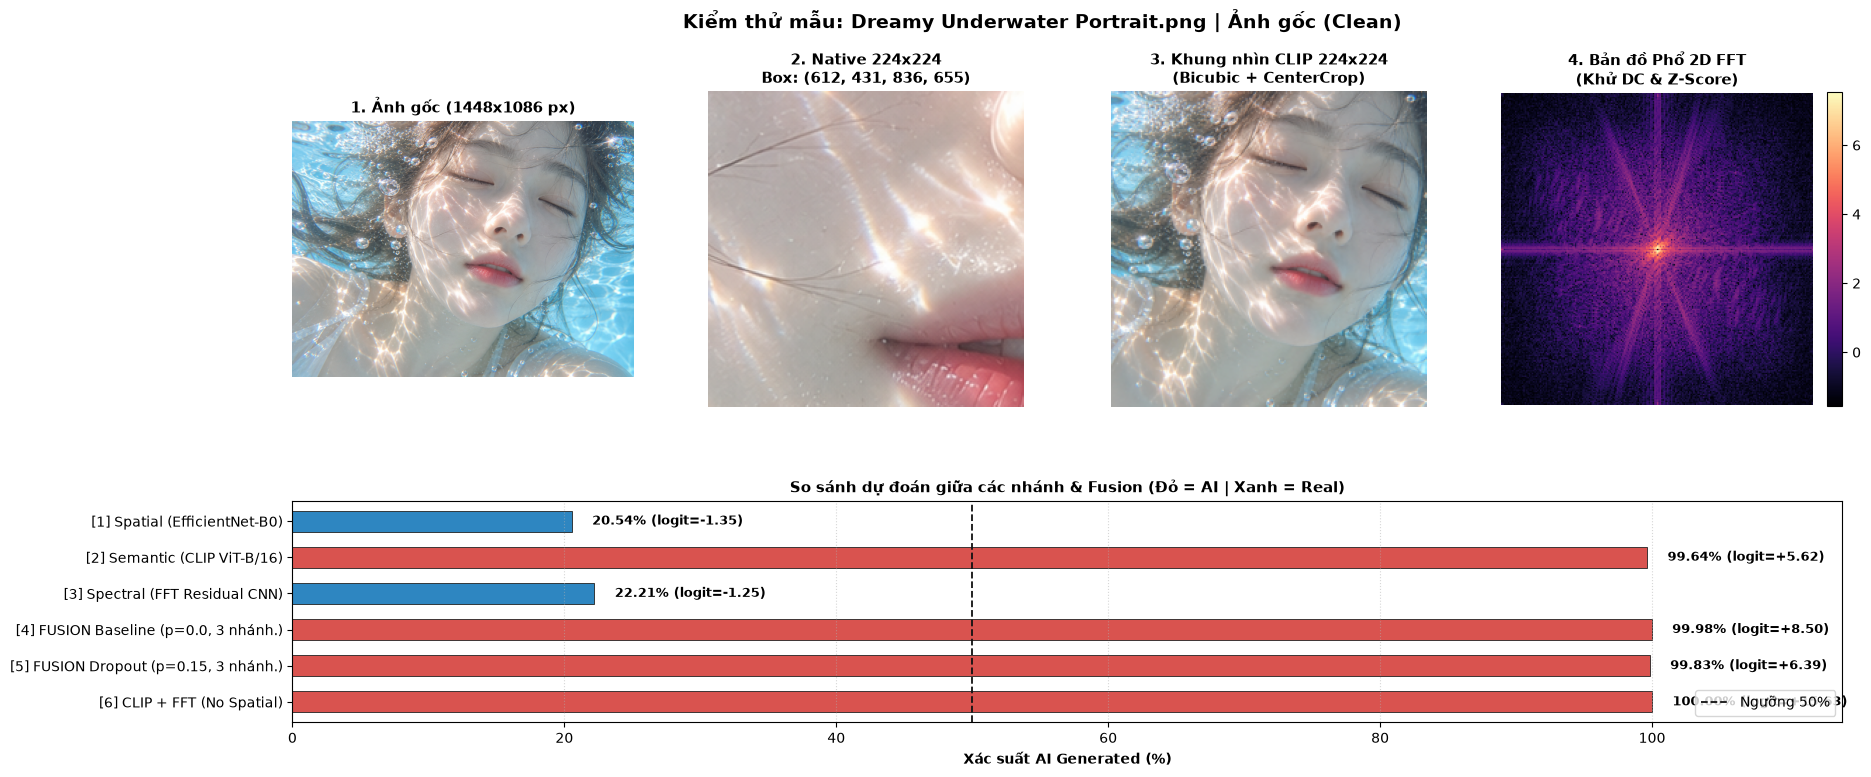

MÔ HÌNH / PHƯƠNG PHÁP                |    LOGIT |     XS AI |   XS THẬT | KẾT LUẬN
----------------------------------------------------------------------------------------------
[1] Spatial (EfficientNet-B0)        |   -1.353 |    20.54% |    79.46% | REAL
[2] Semantic (CLIP ViT-B/16)         |   +5.616 |    99.64% |     0.36% | AI GENERATED
[3] Spectral (FFT Residual CNN)      |   -1.254 |    22.21% |    77.79% | REAL
----------------------------------------------------------------------------------------------
[4] FUSION Baseline (p=0.0, 3 nhánh.) |   +8.502 |    99.98% |     0.02% | >>> AI GENERATED <<<
[5] FUSION Dropout (p=0.15, 3 nhánh.) |   +6.394 |    99.83% |     0.17% | >>> AI GENERATED <<<
[6] CLIP + FFT (No Spatial)          |  +15.626 |   100.00% |     0.00% | >>> AI GENERATED <<<


In [ ]:
MY_CUSTOM_IMAGE = r"C:\Users\THINH\Downloads\dog.jpg"
if os.path.exists(MY_CUSTOM_IMAGE) or (ROOT_DIR / MY_CUSTOM_IMAGE).exists():
    inspect_and_predict(MY_CUSTOM_IMAGE, threshold=0.5, jpeg_quality=None, show_chart=True)
else:
    print("Hãy nhập đường dẫn ảnh hợp lệ vào MY_CUSTOM_IMAGE!")

In [ ]:
# === THỬ NGHIỆM 3: ĐO ĐỘ NHẠY NÉN JPEG TRÊN 1 ẢNH ===
if os.path.exists(MY_CUSTOM_IMAGE) or (ROOT_DIR / MY_CUSTOM_IMAGE).exists():
    inspect_jpeg_sensitivity(MY_CUSTOM_IMAGE)

=== ĐỘ NHẠY NÉN JPEG TRÊN ẢNH: Dreamy Underwater Portrait.png ===
Quality  Spatial%  CLIP%  FFT%  FusBase%  FusDrop%  CLIP+FFT%
  Clean     20.54  99.64 22.21     99.98     99.83      100.0
   Q=90      7.50  99.62 94.84    100.00     99.98      100.0
   Q=70      0.08  99.75 86.03     99.95     97.08      100.0
   Q=50      0.02  99.73 94.72     99.91     95.30      100.0
   Q=30      0.01  99.33 81.71     56.87     59.53      100.0
